### Comparison between SteadierCom and experimental results

In [1]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt

import sys

sys.path.append("../functions/")
import general

import compare_met_exp_sim.correlation as correlation
import compare_met_exp_sim.diagnostic as diagnostic
import compare_met_exp_sim.venturelli2018 as venturelli2018
import compare_met_exp_sim.general_funcs as general_funcs

In [2]:
%load_ext autoreload
%autoreload 2

#### Mapping names to seed ids (seem to have a good overlap)

In [3]:
with open("../data/Venturelli2018/generated/metid2metname.json") as file:
    metid2metname = json.load(file)
    
with open("../data/Venturelli2018/generated/metname2metanetx.json") as file:
    metname2metanetx = json.load(file)
    
with open("../data/Venturelli2018/generated/metname_groups.json") as file:
    metname_groups = json.load(file)

with open("../data/Venturelli2018/generated/metname2group.json") as file:
    metname2group = json.load(file)

with open("../data/Venturelli2018/generated/metid2group.json") as file:
    metid2group = json.load(file)

In [4]:
len(set(metname2metanetx.keys())-set(metid2metname.values()))

33

**Metabolomics**

In [5]:
raw_data_exp,signal_exp = venturelli2018.load_experimental_results()

INFO     | load_experimental_results_venturelli loads and processes metabolomics data from Venturelli et al. 2018 (Dataset EV4) in
	 ../data/Venturelli2018/msb178157-sup-0005-datasetev4.xlsx

	 Results are filtered by metabolites present in models.
INFO     | _assign_groups_and_filter_by_models assigns metabolite groups to the metabolites 
 and filters out metabolites that do not exist in any model.
INFO     | Loading models from Venturelli et al (2018)...


**Load steadiercom results**

In [6]:
simulation_dict = venturelli2018.load_simulation_results(metid2group)

INFO     | load_simulation_results loads simulation results from 
	../output/Venturelli2018/results_steadiercom, 
	../output/Venturelli2018/steadycom and 
	../output/Venturelli2018/smetana
 Only loads results for community 'NONE' (full community)
INFO     | _prepare_sim_met_venturelli removes environment from receivers and all compounds that are not found in metabolomics and map to AGORA identifiers
INFO     | _prepare_sim_met_venturelli removes environment from receivers and all compounds that are not found in metabolomics and map to AGORA identifiers
INFO     | _prepare_sim_met_venturelli removes environment from receivers and all compounds that are not found in metabolomics and map to AGORA identifiers
INFO     | _prepare_sim_met_venturelli removes environment from donors and all compounds that are not found in metabolomics and map to AGORA identifiers
INFO     | _prepare_sim_met_venturelli removes environment from donors and all compounds that are not found in metabolomics and map 

## Correlation analysis - continuous data 


**Motivation**: Seeing if there is a correlation between simulated and experimental results.

**Experimental data**: Relative concentration change of compound in log2. According to Venturelli et al. (2018), log2(C_diff) between -1 and 1 is non-significant. 

**Simulated data**: From three different simulation methods: steadiercom, steadycom and smetana and different configurations of these. The metric used for meassure the strength of a met-member interaction depends on the simulation method. For example for steadiercom there are three options: frequency, rate, mass_rate. 
- Processing: 
    - Removes compounds that were not in the Venturelli et al. study from simulation results.
    - Adjusts metabolite and member names for merging with experimental data. 

**Expected results:**
*NOTE: Consumption in the experimental data is negative while production is positive, but in the simulated data consumption/production are both positive. Because of this:*
- We expect a **negative trend** for receiving rate/frequency with change in concentration. 
- We expect a **positive trend** for donating rate/frequency with change in concentration.  

**Methods:**
- Correlation: Kendall's Tau - A non-parametric and rank-based method - better at handling ties between values on either x-axis or y-axis compared to Spearman. Since the metrics frequency and MUS give a maximum value of 1 we end up with many ties in our datasets.

### Best predictors of receiver-met relationship

In [7]:
results_corr_df,results_corr_member_df,results_corr_met_df = venturelli2018.find_correlations(simulation_dict,signal_exp)

In [8]:

receiver_or_donor = "receiver"
mask = (results_corr_df.index.get_level_values("role")==receiver_or_donor)
best_predictor = results_corr_df[mask].sort_values('r')
best_predictor

r  \
role     simulation_method condition                              agg_method metric                          
receiver steadycom         SteadyCom - Nothing fixed              sum        rate?               -0.151821   
         steadiercom       SteadierCom - fixed growth             sum        frequency           -0.135178   
                           SteadierCom - fixed growth & abundance sum        frequency           -0.135108   
                           SteadierCom - fixed growth             sum        frequency*mass_rate -0.128243   
         steadycom         SteadyCom - Fixed  abundance           sum        rate?               -0.123331   
         steadiercom       SteadierCom - fixed abundance          sum        frequency*mass_rate -0.114441   
                           SteadierCom - fixed growth & abundance sum        frequency*mass_rate -0.113272   
                           SteadierCom - fixed abundance          sum        frequency           -0.101581   
         smetana           Smetana                                sum        mus                  0.333333   

                                                                                                   p-value  \
role     simulation_method condition                              agg_method metric                          
receiver steadycom         SteadyCom - Nothing fixed              sum        rate?                0.011031   
         steadiercom       SteadierCom - fixed growth             sum        frequency            0.008727   
                           SteadierCom - fixed growth & abundance sum        frequency            0.013217   
                           SteadierCom - fixed growth             sum        frequency*mass_rate  0.012252   
         steadycom         SteadyCom - Fixed  abundance           sum        rate?                0.034528   
         steadiercom       SteadierCom - fixed abundance          sum        frequency*mass_rate  0.031185   
                           SteadierCom - fixed growth & abundance sum        frequency*mass_rate  0.031326   
                           SteadierCom - fixed abundance          sum        frequency            0.066319   
         smetana           Smetana                                sum        mus                  0.381349   

                                                                                                  datapoints  
role     simulation_method condition                              agg_method metric                           
receiver steadycom         SteadyCom - Nothing fixed              sum        rate?                     128.0  
         steadiercom       SteadierCom - fixed growth             sum        frequency                 173.0  
                           SteadierCom - fixed growth & abundance sum        frequency                 164.0  
                           SteadierCom - fixed growth             sum        frequency*mass_rate       173.0  
         steadycom         SteadyCom - Fixed  abundance           sum        rate?                     134.0  
         steadiercom       SteadierCom - fixed abundance          sum        frequency*mass_rate       161.0  
                           SteadierCom - fixed growth & abundance sum        frequency*mass_rate       164.0  
                           SteadierCom - fixed abundance          sum        frequency                 161.0  
         smetana           Smetana                                sum        mus                         7.0

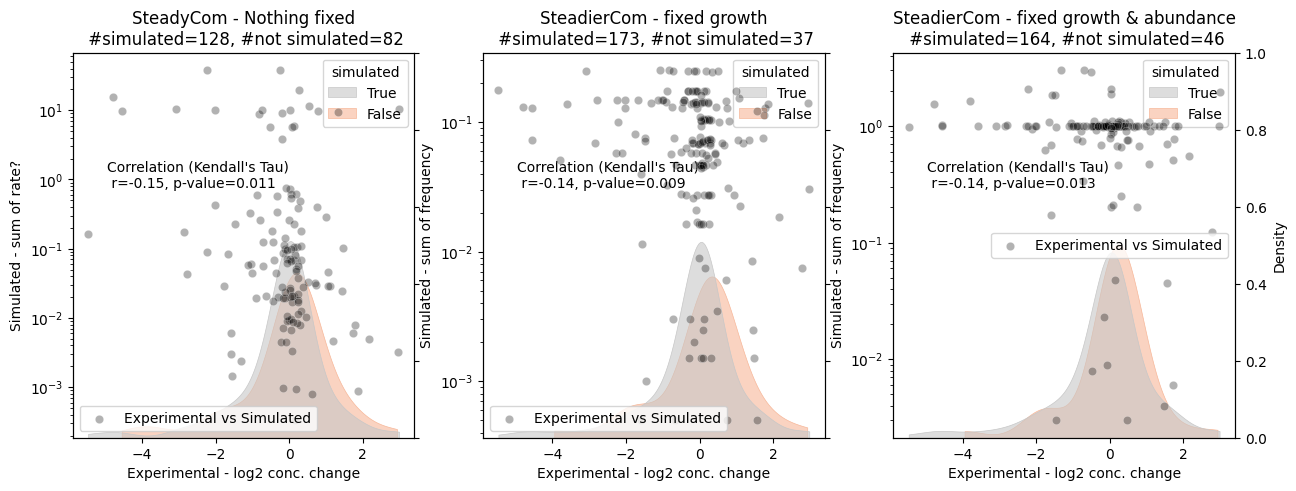

In [9]:
fig,axs,axs_twin = correlation.plot_scatterplots_from_corr(best_predictor.head(3), 
                                        simulation_dict,
                                        signal_exp,
                                        member_or_met=None)


### Best predictors of donor-met relationship

In [10]:

receiver_or_donor = "donor"
mask = (results_corr_df.index.get_level_values("role")==receiver_or_donor)
best_predictor = results_corr_df[mask].sort_values('r',ascending=False)
best_predictor


r  \
role  simulation_method condition                              agg_method metric                          
donor steadycom         SteadyCom - Nothing fixed              sum        rate?                0.284211   
      steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate  0.060870   
                                                                          frequency            0.016619   
      steadycom         SteadyCom - Fixed  abundance           sum        rate?                0.000000   
      steadiercom       SteadierCom - fixed abundance          sum        frequency           -0.011671   
                        SteadierCom - fixed growth & abundance sum        frequency           -0.014367   
                                                                          frequency*mass_rate -0.036199   
                        SteadierCom - fixed abundance          sum        frequency*mass_rate -0.080338   
      smetana           Smetana                                sum        mus                 -0.233550   

                                                                                                p-value  \
role  simulation_method condition                              agg_method metric                          
donor steadycom         SteadyCom - Nothing fixed              sum        rate?                0.085502   
      steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate  0.550846   
                                                                          frequency            0.871921   
      steadycom         SteadyCom - Fixed  abundance           sum        rate?                1.000000   
      steadiercom       SteadierCom - fixed abundance          sum        frequency            0.911378   
                        SteadierCom - fixed growth & abundance sum        frequency            0.880791   
                                                                          frequency*mass_rate  0.704857   
                        SteadierCom - fixed abundance          sum        frequency*mass_rate  0.442081   
      smetana           Smetana                                sum        mus                  0.537453   

                                                                                               datapoints  
role  simulation_method condition                              agg_method metric                           
donor steadycom         SteadyCom - Nothing fixed              sum        rate?                      20.0  
      steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate        46.0  
                                                                          frequency                  46.0  
      steadycom         SteadyCom - Fixed  abundance           sum        rate?                      24.0  
      steadiercom       SteadierCom - fixed abundance          sum        frequency                  44.0  
                        SteadierCom - fixed growth & abundance sum        frequency                  52.0  
                                                                          frequency*mass_rate        52.0  
                        SteadierCom - fixed abundance          sum        frequency*mass_rate        44.0  
      smetana           Smetana                                sum        mus                         6.0

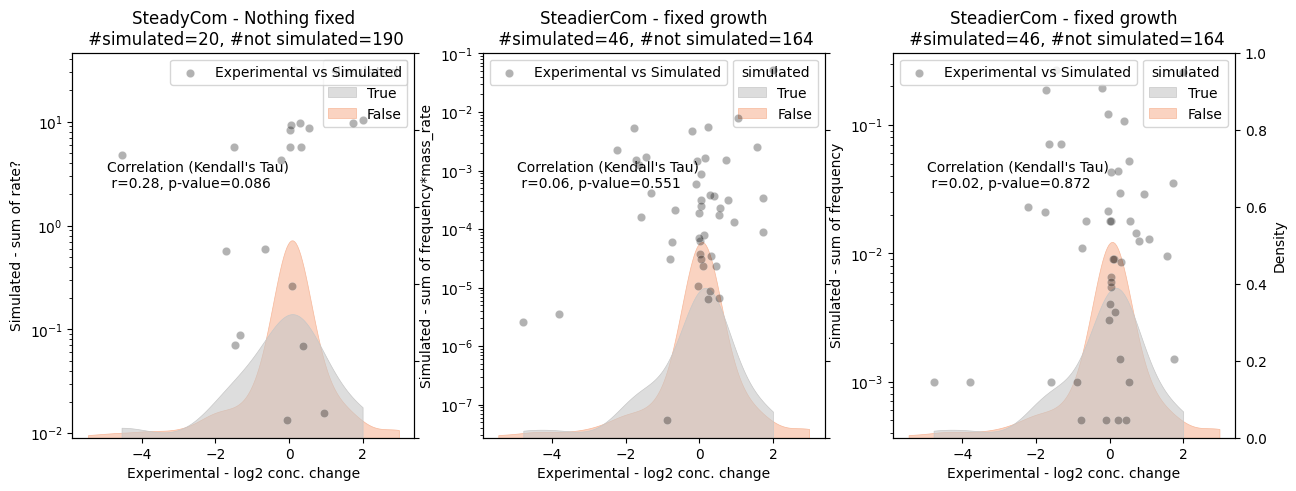

In [11]:
fig,axs,axs_twin = correlation.plot_scatterplots_from_corr(best_predictor.head(3), 
                                        simulation_dict,
                                        signal_exp,
                                        member_or_met=None)



### Correlation by member/metabolite

In [12]:
mask = ((results_corr_member_df["p-value"]<=0.05) 
        & (results_corr_member_df.index.get_level_values("role")=="receiver"))
results_corr_member_df_red = results_corr_member_df[mask].sort_values("r")
results_corr_member_df_red

r  \
role     simulation_method condition                              agg_method metric              member             
receiver steadycom         SteadyCom - Fixed  abundance           sum        rate?               CA     -0.733333   
                           SteadyCom - Nothing fixed              sum        rate?               CA     -0.733333   
         steadiercom       SteadierCom - fixed abundance          sum        frequency*mass_rate CA     -0.527273   
                           SteadierCom - fixed growth & abundance sum        frequency*mass_rate CA     -0.527273   
         steadycom         SteadyCom - Nothing fixed              sum        rate?               CH     -0.403509   
         steadiercom       SteadierCom - fixed growth & abundance sum        frequency*mass_rate FP     -0.390476   
                                                                             frequency           CH     -0.356466   
         steadycom         SteadyCom - Fixed  abundance           sum        rate?               CH     -0.333333   

                                                                                                          p-value  \
role     simulation_method condition                              agg_method metric              member             
receiver steadycom         SteadyCom - Fixed  abundance           sum        rate?               CA      0.002213   
                           SteadyCom - Nothing fixed              sum        rate?               CA      0.002213   
         steadiercom       SteadierCom - fixed abundance          sum        frequency*mass_rate CA      0.026384   
                           SteadierCom - fixed growth & abundance sum        frequency*mass_rate CA      0.026384   
         steadycom         SteadyCom - Nothing fixed              sum        rate?               CH      0.015819   
         steadiercom       SteadierCom - fixed growth & abundance sum        frequency*mass_rate FP      0.046292   
                                                                             frequency           CH      0.032270   
         steadycom         SteadyCom - Fixed  abundance           sum        rate?               CH      0.049049   

                                                                                                         datapoints  \
role     simulation_method condition                              agg_method metric              member               
receiver steadycom         SteadyCom - Fixed  abundance           sum        rate?               CA            10.0   
                           SteadyCom - Nothing fixed              sum        rate?               CA            10.0   
         steadiercom       SteadierCom - fixed abundance          sum        frequency*mass_rate CA            11.0   
                           SteadierCom - fixed growth & abundance sum        frequency*mass_rate CA            11.0   
         steadycom         SteadyCom - Nothing fixed              sum        rate?               CH            19.0   
         steadiercom       SteadierCom - fixed growth & abundance sum        frequency*mass_rate FP            15.0   
                                                                             frequency           CH            20.0   
         steadycom         SteadyCom - Fixed  abundance           sum        rate?               CH            19.0   

                                                                                                         p-value corrected  \
role     simulation_method condition                              agg_method metric              member                      
receiver steadycom         SteadyCom - Fixed  abundance           sum        rate?               CA               0.026554   
                           SteadyCom - Nothing fixed              sum        rate?               CA               0.026554   
         steadiercom       SteadierCom - fixed abundance          sum      

#### Best predictor of each member in receiver-metabolite predictors

In [13]:
mask = ~results_corr_member_df_red.index.get_level_values('member').duplicated(keep='first')
best_predicted_members = results_corr_member_df_red[mask]
best_predicted_members


r  \
role     simulation_method condition                              agg_method metric              member             
receiver steadycom         SteadyCom - Fixed  abundance           sum        rate?               CA     -0.733333   
                           SteadyCom - Nothing fixed              sum        rate?               CH     -0.403509   
         steadiercom       SteadierCom - fixed growth & abundance sum        frequency*mass_rate FP     -0.390476   

                                                                                                          p-value  \
role     simulation_method condition                              agg_method metric              member             
receiver steadycom         SteadyCom - Fixed  abundance           sum        rate?               CA      0.002213   
                           SteadyCom - Nothing fixed              sum        rate?               CH      0.015819   
         steadiercom       SteadierCom - fixed growth & abundance sum        frequency*mass_rate FP      0.046292   

                                                                                                         datapoints  \
role     simulation_method condition                              agg_method metric              member               
receiver steadycom         SteadyCom - Fixed  abundance           sum        rate?               CA            10.0   
                           SteadyCom - Nothing fixed              sum        rate?               CH            19.0   
         steadiercom       SteadierCom - fixed growth & abundance sum        frequency*mass_rate FP            15.0   

                                                                                                         p-value corrected  \
role     simulation_method condition                              agg_method metric              member                      
receiver steadycom         SteadyCom - Fixed  abundance           sum        rate?               CA               0.026554   
                           SteadyCom - Nothing fixed              sum        rate?               CH               0.189827   
         steadiercom       SteadierCom - fixed growth & abundance sum        frequency*mass_rate FP               0.555510   

                                                                                                         number comparisons  
role     simulation_method condition                              agg_method metric              member                      
receiver steadycom         SteadyCom - Fixed  abundance           sum        rate?               CA                      12  
                           SteadyCom - Nothing fixed              sum        rate?               CH                      12  
         steadiercom       SteadierCom - fixed growth & abundance sum        frequency*mass_rate FP                      12

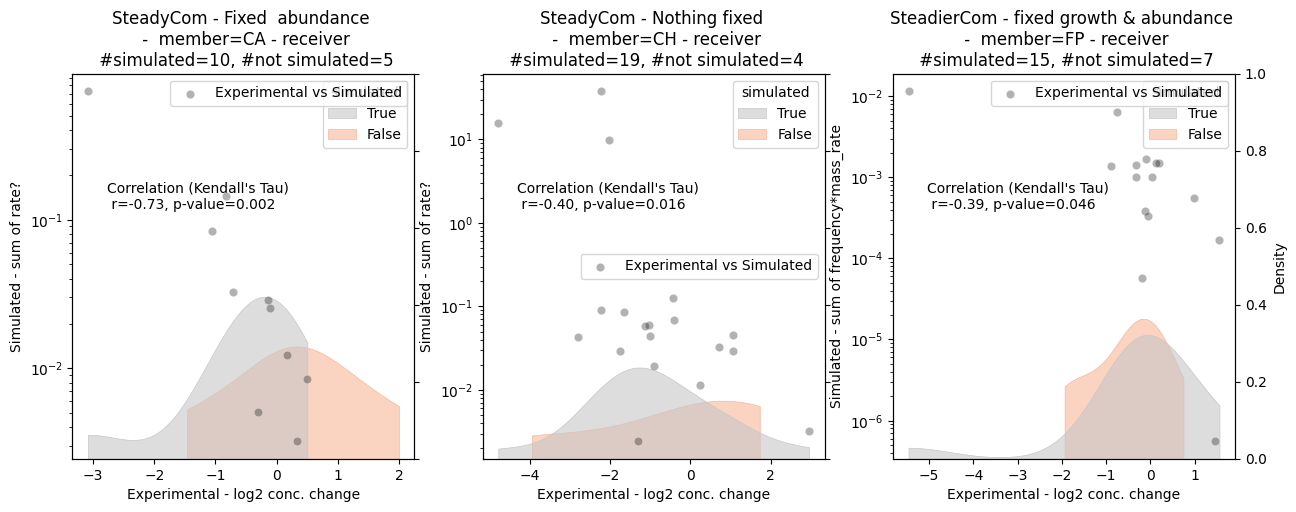

In [14]:
_,_,_ = correlation.plot_scatterplots_from_corr(best_predicted_members, simulation_dict,signal_exp,member_or_met="member",met_column="met_group")


In [15]:
mask = ((results_corr_met_df["p-value"]<=0.05) 
        & (results_corr_met_df.index.get_level_values("role")=="receiver"))
results_corr_met_df_red = results_corr_met_df[mask].sort_values("r")
results_corr_met_df_red

r  \
role     simulation_method condition                              agg_method metric              met_group                  
receiver steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate Uridine pool   -0.866667   
                           SteadierCom - fixed growth & abundance sum        frequency           Glutamate pool -0.745356   
                                                                                                 Uracil pool     0.618590   

                                                                                                                  p-value  \
role     simulation_method condition                              agg_method metric              met_group                  
receiver steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate Uridine pool    0.016667   
                           SteadierCom - fixed growth & abundance sum        frequency           Glutamate pool  0.044065   
                                                                                                 Uracil pool     0.044383   

                                                                                                                 datapoints  \
role     simulation_method condition                              agg_method metric              met_group                    
receiver steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate Uridine pool           6.0   
                           SteadierCom - fixed growth & abundance sum        frequency           Glutamate pool         6.0   
                                                                                                 Uracil pool            8.0   

                                                                                                                 p-value corrected  \
role     simulation_method condition                              agg_method metric              met_group                           
receiver steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate Uridine pool             0.583333   
                           SteadierCom - fixed growth & abundance sum        frequency           Glutamate pool           1.542289   
                                                                                                 Uracil pool              1.553419   

                                                                                                                 number comparisons  
role     simulation_method condition                              agg_method metric              met_group                           
receiver steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate Uridine pool                    35  
                           SteadierCom - fixed growth & abundance sum        frequency           Glutamate pool                  35  
                                                                                                 Uracil pool                     35

In [16]:
mask = ~results_corr_met_df_red.index.get_level_values('met_group').duplicated(keep='first')
best_predicted_mets = results_corr_met_df_red[mask]
best_predicted_mets

r  \
role     simulation_method condition                              agg_method metric              met_group                  
receiver steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate Uridine pool   -0.866667   
                           SteadierCom - fixed growth & abundance sum        frequency           Glutamate pool -0.745356   
                                                                                                 Uracil pool     0.618590   

                                                                                                                  p-value  \
role     simulation_method condition                              agg_method metric              met_group                  
receiver steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate Uridine pool    0.016667   
                           SteadierCom - fixed growth & abundance sum        frequency           Glutamate pool  0.044065   
                                                                                                 Uracil pool     0.044383   

                                                                                                                 datapoints  \
role     simulation_method condition                              agg_method metric              met_group                    
receiver steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate Uridine pool           6.0   
                           SteadierCom - fixed growth & abundance sum        frequency           Glutamate pool         6.0   
                                                                                                 Uracil pool            8.0   

                                                                                                                 p-value corrected  \
role     simulation_method condition                              agg_method metric              met_group                           
receiver steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate Uridine pool             0.583333   
                           SteadierCom - fixed growth & abundance sum        frequency           Glutamate pool           1.542289   
                                                                                                 Uracil pool              1.553419   

                                                                                                                 number comparisons  
role     simulation_method condition                              agg_method metric              met_group                           
receiver steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate Uridine pool                    35  
                           SteadierCom - fixed growth & abundance sum        frequency           Glutamate pool                  35  
                                                                                                 Uracil pool                     35

/Users/idunmariaburgos/SteadierCom/case_studies/notebooks/../functions/compare_met_exp_sim/correlation.py:158: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(data=exp_sim_combined_is_nan,
/Users/idunmariaburgos/SteadierCom/case_studies/notebooks/../functions/compare_met_exp_sim/correlation.py:158: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(data=exp_sim_combined_is_nan,


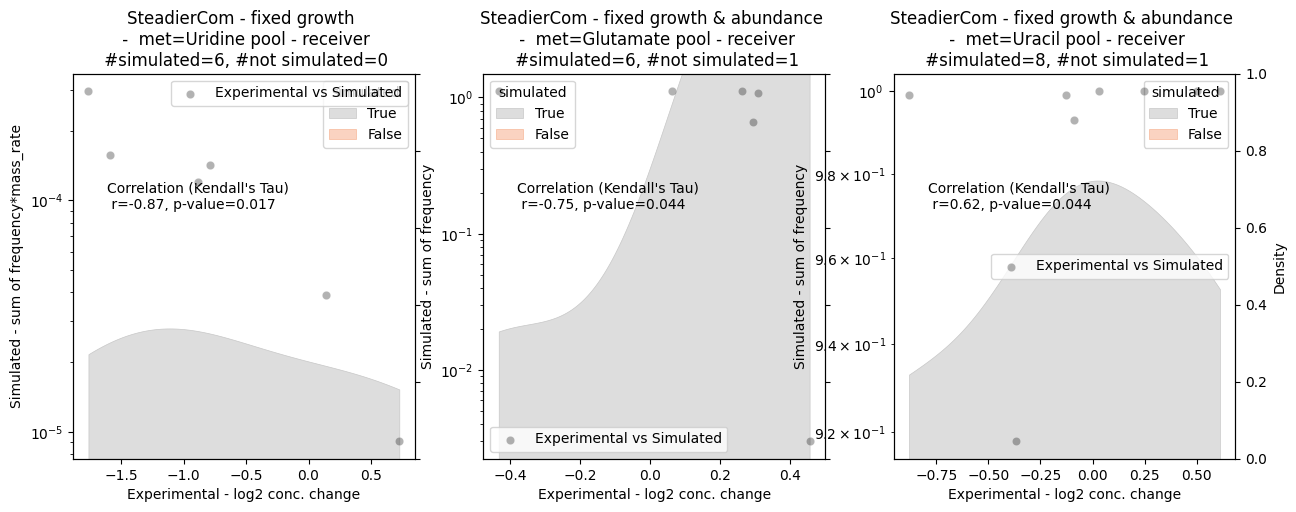

In [17]:
_,_,_ = correlation.plot_scatterplots_from_corr(best_predicted_mets, simulation_dict,signal_exp,member_or_met="met",met_column="met_group")


###  SteadierCom results - frequency

INFO     | make_scatterplot removes nan values in 'simulated' column for scatterplot and uses all values for density plot.
INFO     | merge_sim_exp removes compounds not in experimental data
INFO     | find_correlation uses dropna() to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes compounds not in experimental data
INFO     | make_scatterplot removes nan values in 'simulated' column for scatterplot and uses all values for density plot.
INFO     | merge_sim_exp removes compounds not in experimental data
INFO     | find_correlation uses dropna() to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes compounds not in experimental data


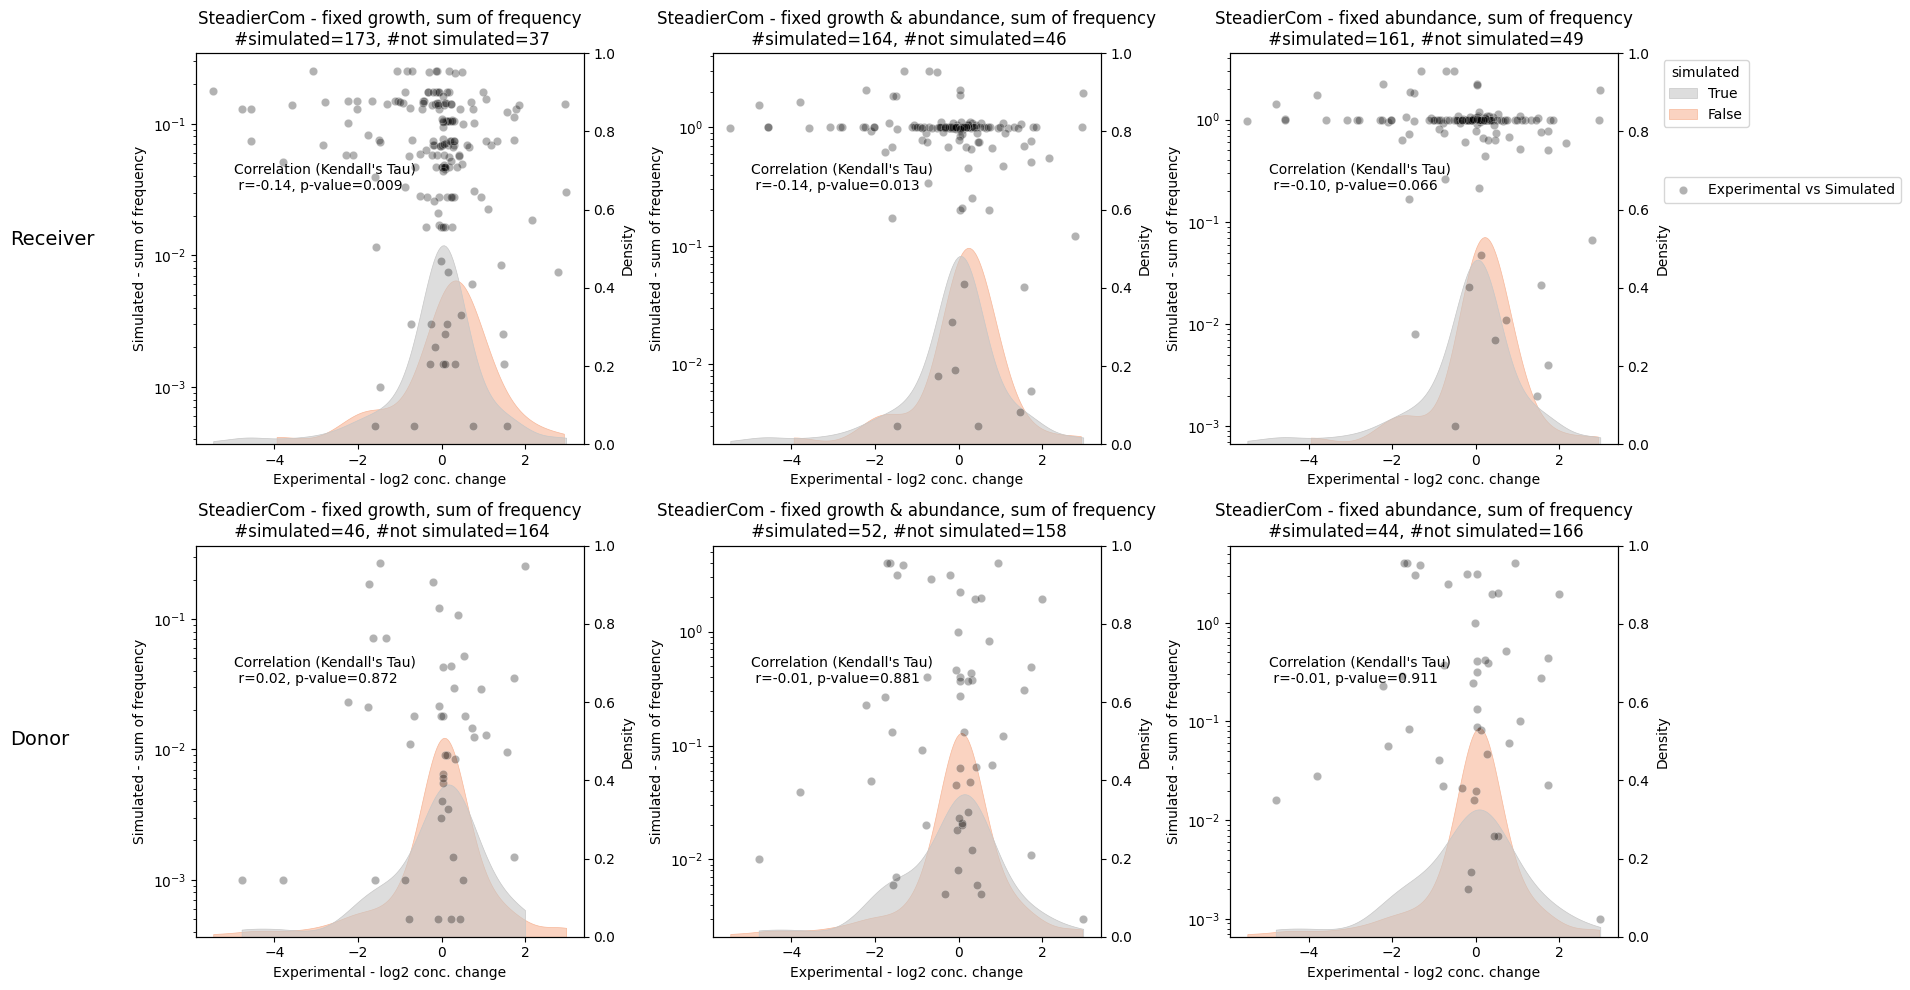

In [18]:
fig, axs, twin_axes = correlation.make_scatterplots_simulation_method(simulation_dict, 
                                                signal_exp,
                                                simulation_method="steadiercom",
                                                metric="frequency",
                                                )

# Diagnostic analysis - Binary data

In [19]:
support_df = diagnostic.identify_support(signal_exp)
support_df.sort_index(ascending=False)

positive_support  negative_support  total  no-skill line
receiver 1.00                34               176    210       0.161905
         0.50                47               163    210       0.223810
         0.25                59               151    210       0.280952
donor    1.00                22               188    210       0.104762
         0.50                42               168    210       0.200000
         0.25                65               145    210       0.309524

## Precision-Recall curves

In [20]:
results_pr_auc_df = venturelli2018.find_pvalues_of_PR(simulation_dict,signal_exp)

INFO     | merge_sim_exp removes compounds not in experimental data
INFO     | merge_sim_exp removes compounds not in experimental data


### Best predictor of receiver-metabolite relationships

In [21]:
mask_best = ((results_pr_auc_df.p_value<0.05) & (results_pr_auc_df.index.get_level_values("role")=="receiver"))

best_pr_predictors = results_pr_auc_df[mask_best].sort_values(by="p_value")
best_pr_predictors


p_value
role     simulation_method condition                              agg_method metric              exp_thresh         
receiver steadiercom       SteadierCom - fixed growth & abundance sum        frequency           0.5          0.0002
                           SteadierCom - fixed abundance          sum        frequency           0.5          0.0011
                           SteadierCom - fixed growth & abundance sum        frequency           1.0          0.0016
         steadycom         SteadyCom - Fixed  abundance           sum        rate?               0.5          0.0050
         steadiercom       SteadierCom - fixed growth             sum        frequency           0.5          0.0051
                           SteadierCom - fixed abundance          sum        frequency           1.0          0.0078
                           SteadierCom - fixed growth             sum        frequency*mass_rate 0.5          0.0079
                           SteadierCom - fixed growth & abundance sum        frequency*mass_rate 0.5          0.0112
         steadycom         SteadyCom - Nothing fixed              sum        rate?               0.5          0.0198
                           SteadyCom - Fixed  abundance           sum        rate?               1.0          0.0207
         steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate 1.0          0.0239
                           SteadierCom - fixed abundance          sum        frequency*mass_rate 0.5          0.0265
                           SteadierCom - fixed growth & abundance sum        frequency*mass_rate 1.0          0.0388
         steadycom         SteadyCom - Nothing fixed              sum        rate?               1.0          0.0468

INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes compounds not in experimental data
INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes compounds not in experimental data


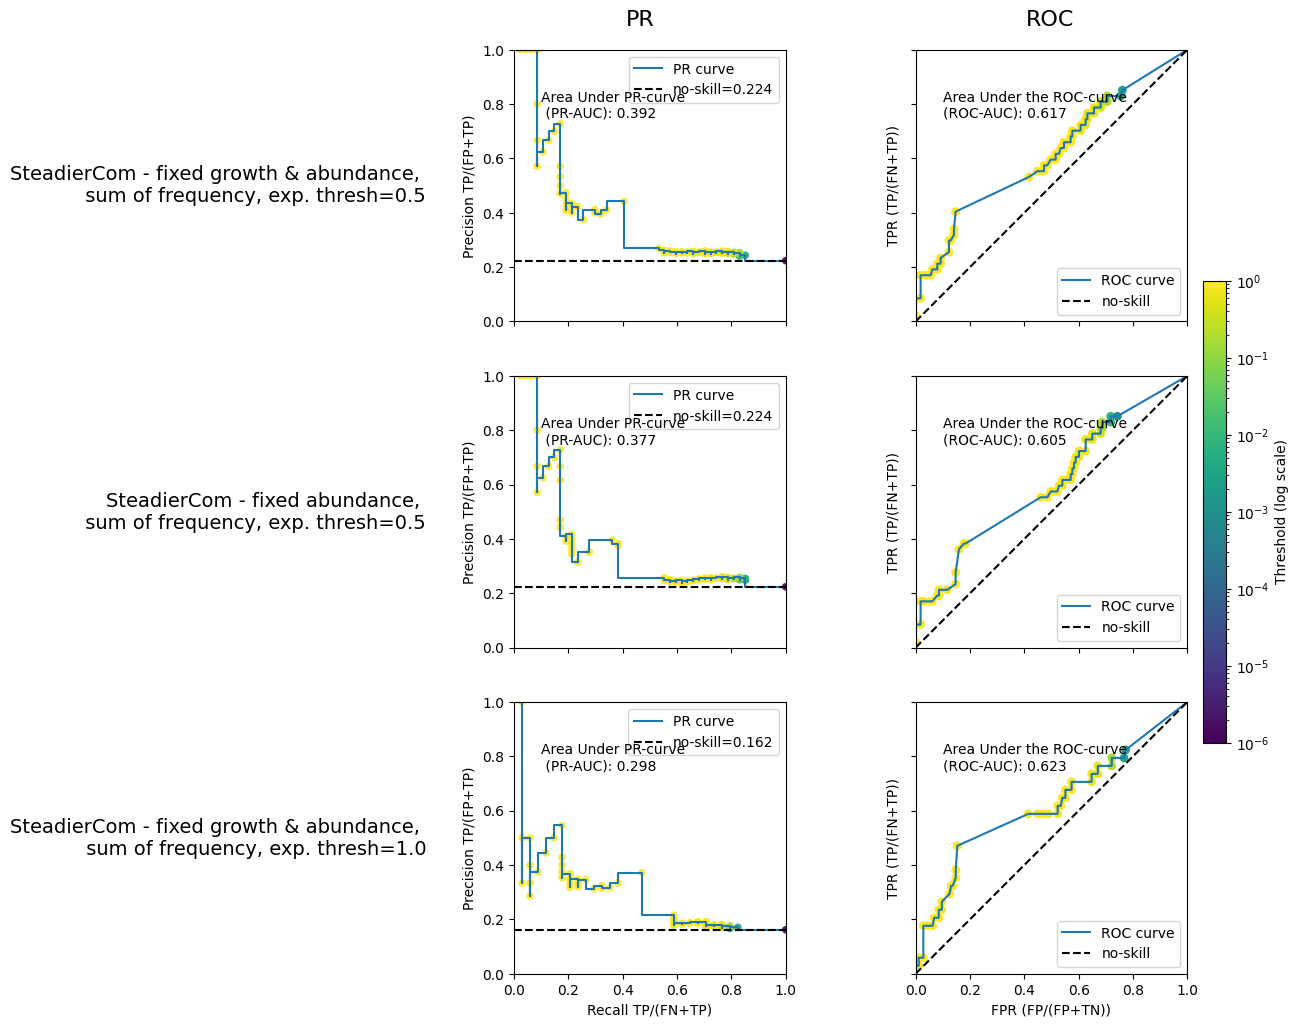

In [22]:
fig, axs = diagnostic.plot_diagnostic_curves_pvalues(best_pr_predictors.head(3),
                                                  simulation_dict,
                                                  signal_exp,
                                                  receiver_or_donor="receiver")

### Best predictor of donor-metabolite relationships

In [23]:
mask_best = ((results_pr_auc_df.p_value<0.05) & (results_pr_auc_df.index.get_level_values("role")=="donor"))

best_pr_predictors = results_pr_auc_df[mask_best].sort_values(by="p_value")
best_pr_predictors


p_value
role  simulation_method condition                  agg_method metric              exp_thresh         
donor steadiercom       SteadierCom - fixed growth sum        frequency*mass_rate 1.0          0.0109
                                                                                  0.5          0.0419

INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes compounds not in experimental data
INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes compounds not in experimental data


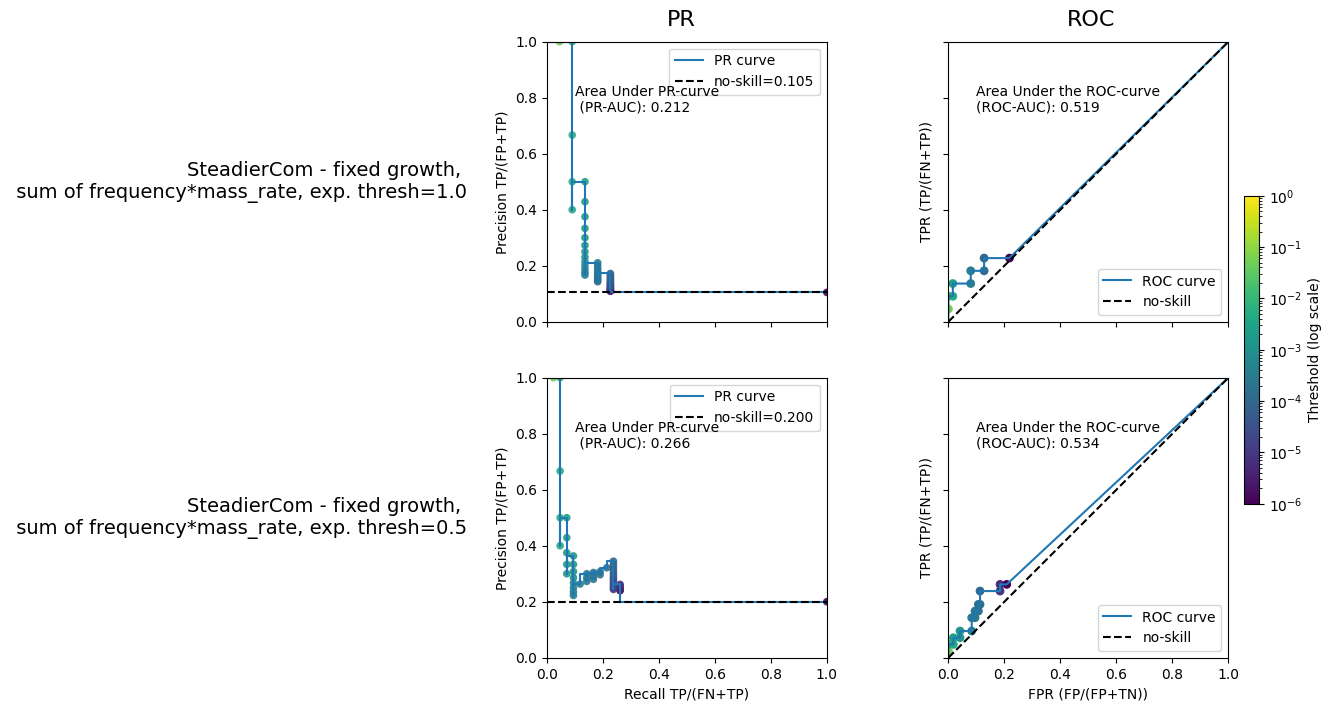

In [24]:
fig, axs = diagnostic.plot_diagnostic_curves_pvalues(best_pr_predictors.head(3),
                                                  simulation_dict,
                                                  signal_exp,
                                                  receiver_or_donor="donor")

INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes compounds not in experimental data


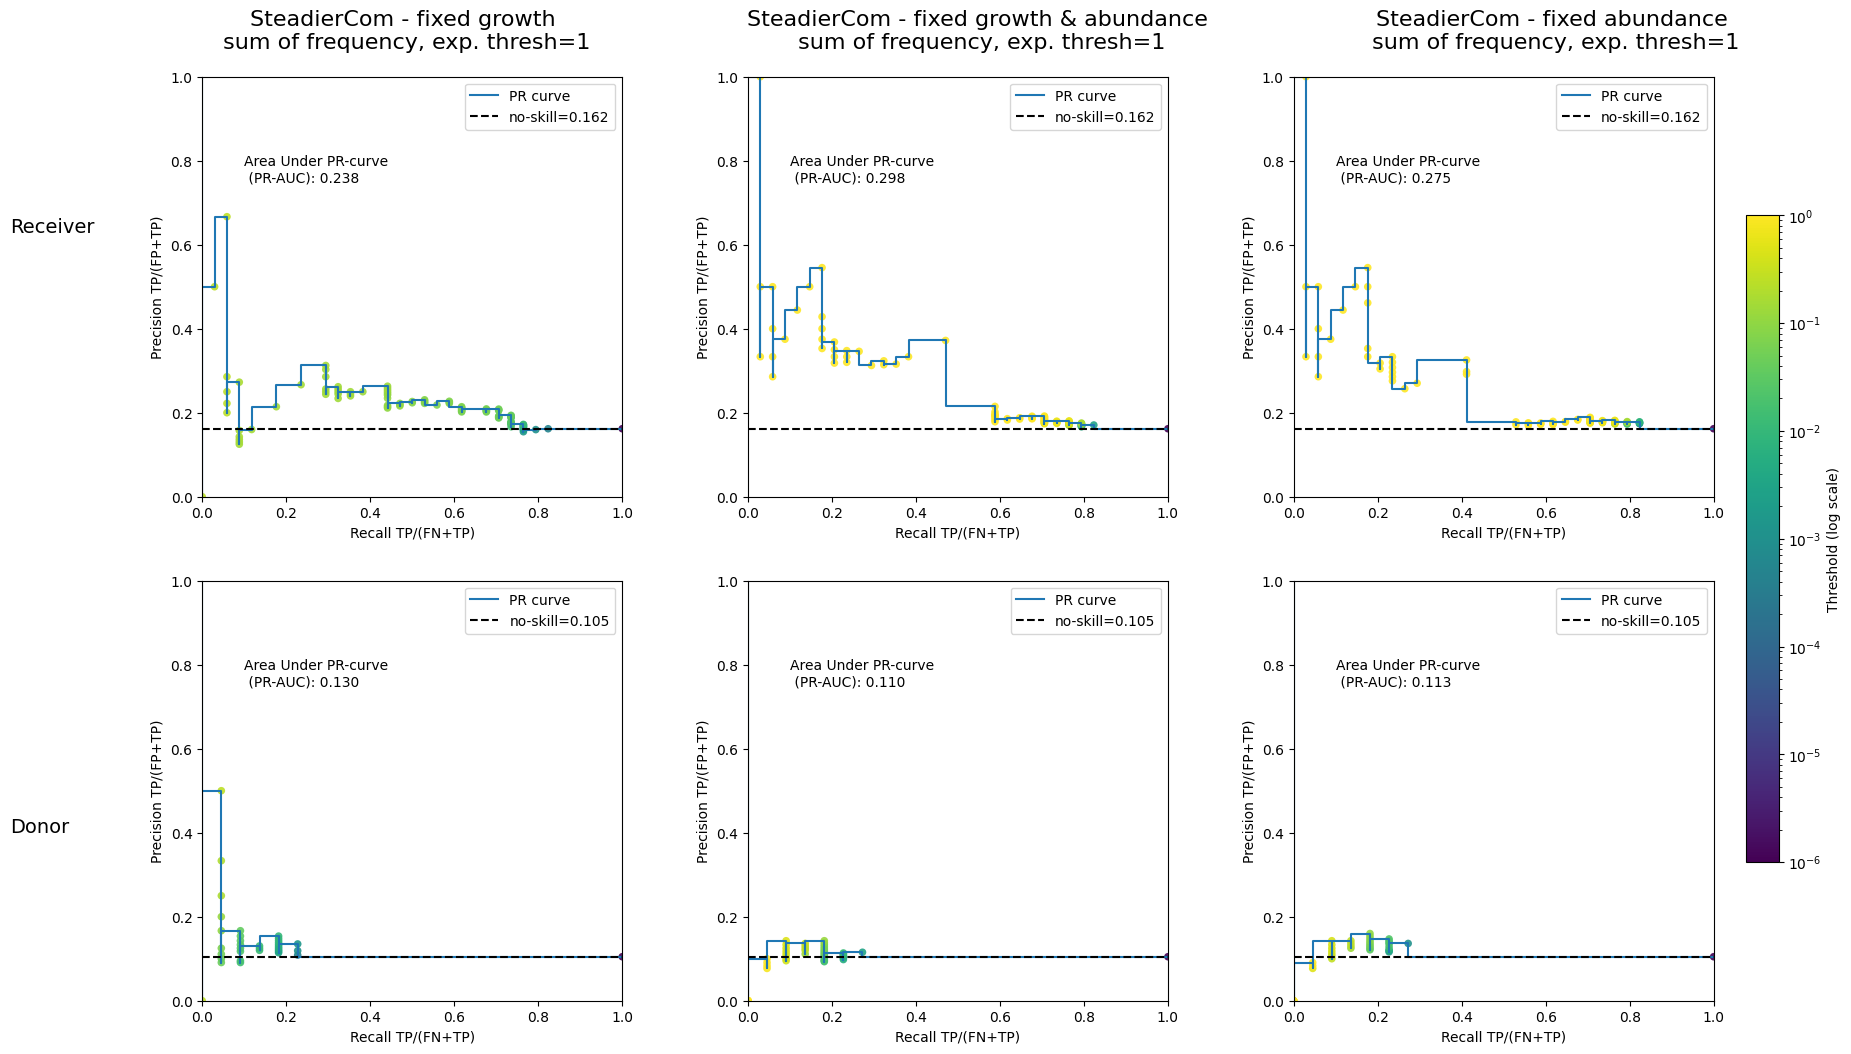

In [25]:
fig,axs = diagnostic.plot_diagnostic_curves_method(simulation_dict,
                                                    signal_exp,
                                                    simulation_method="steadiercom",
                                                    metric="frequency",
                                                    met_column="met_group",
                                                    agg_method="sum")

INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes compounds not in experimental data


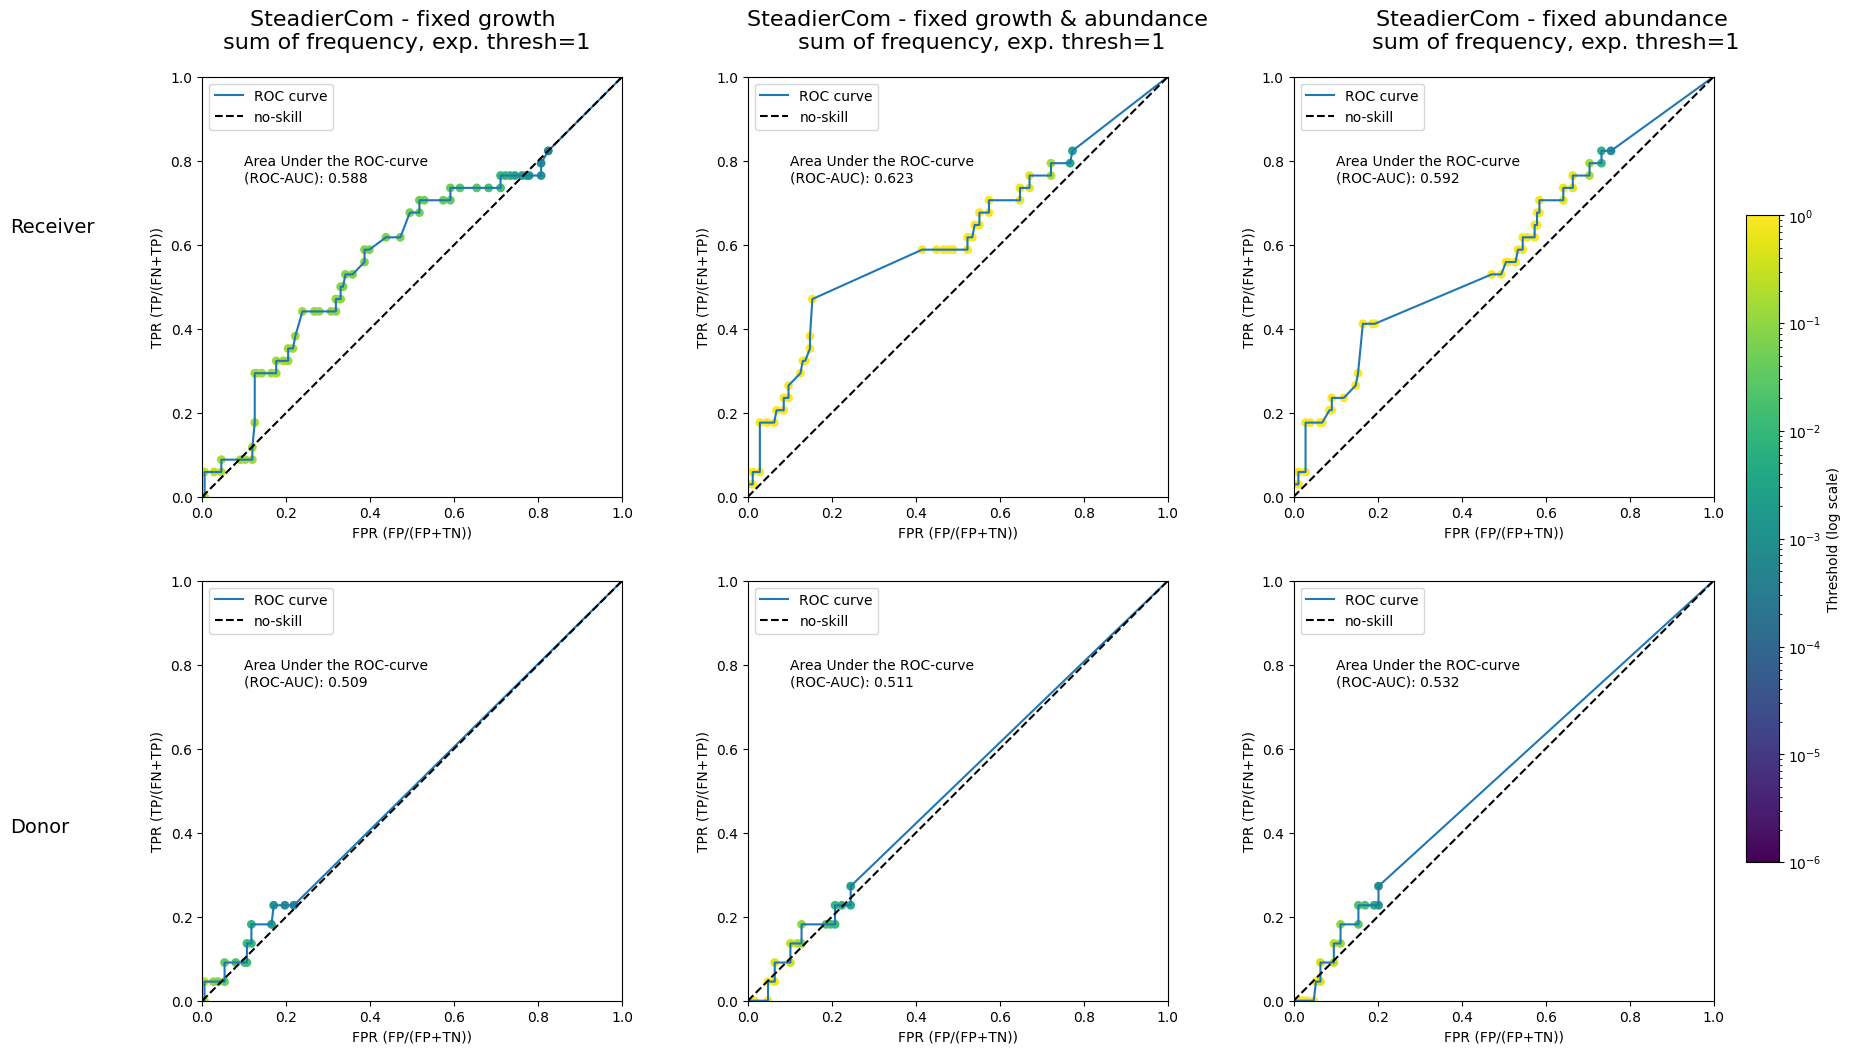

In [26]:
fig,axs = diagnostic.plot_diagnostic_curves_method(simulation_dict,
                                                    signal_exp,
                                                    simulation_method="steadiercom",
                                                    PR_or_ROC="ROC",
                                                    metric="frequency",
                                                    met_column="met_group",
                                                    agg_method="sum")

INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes compounds not in experimental data


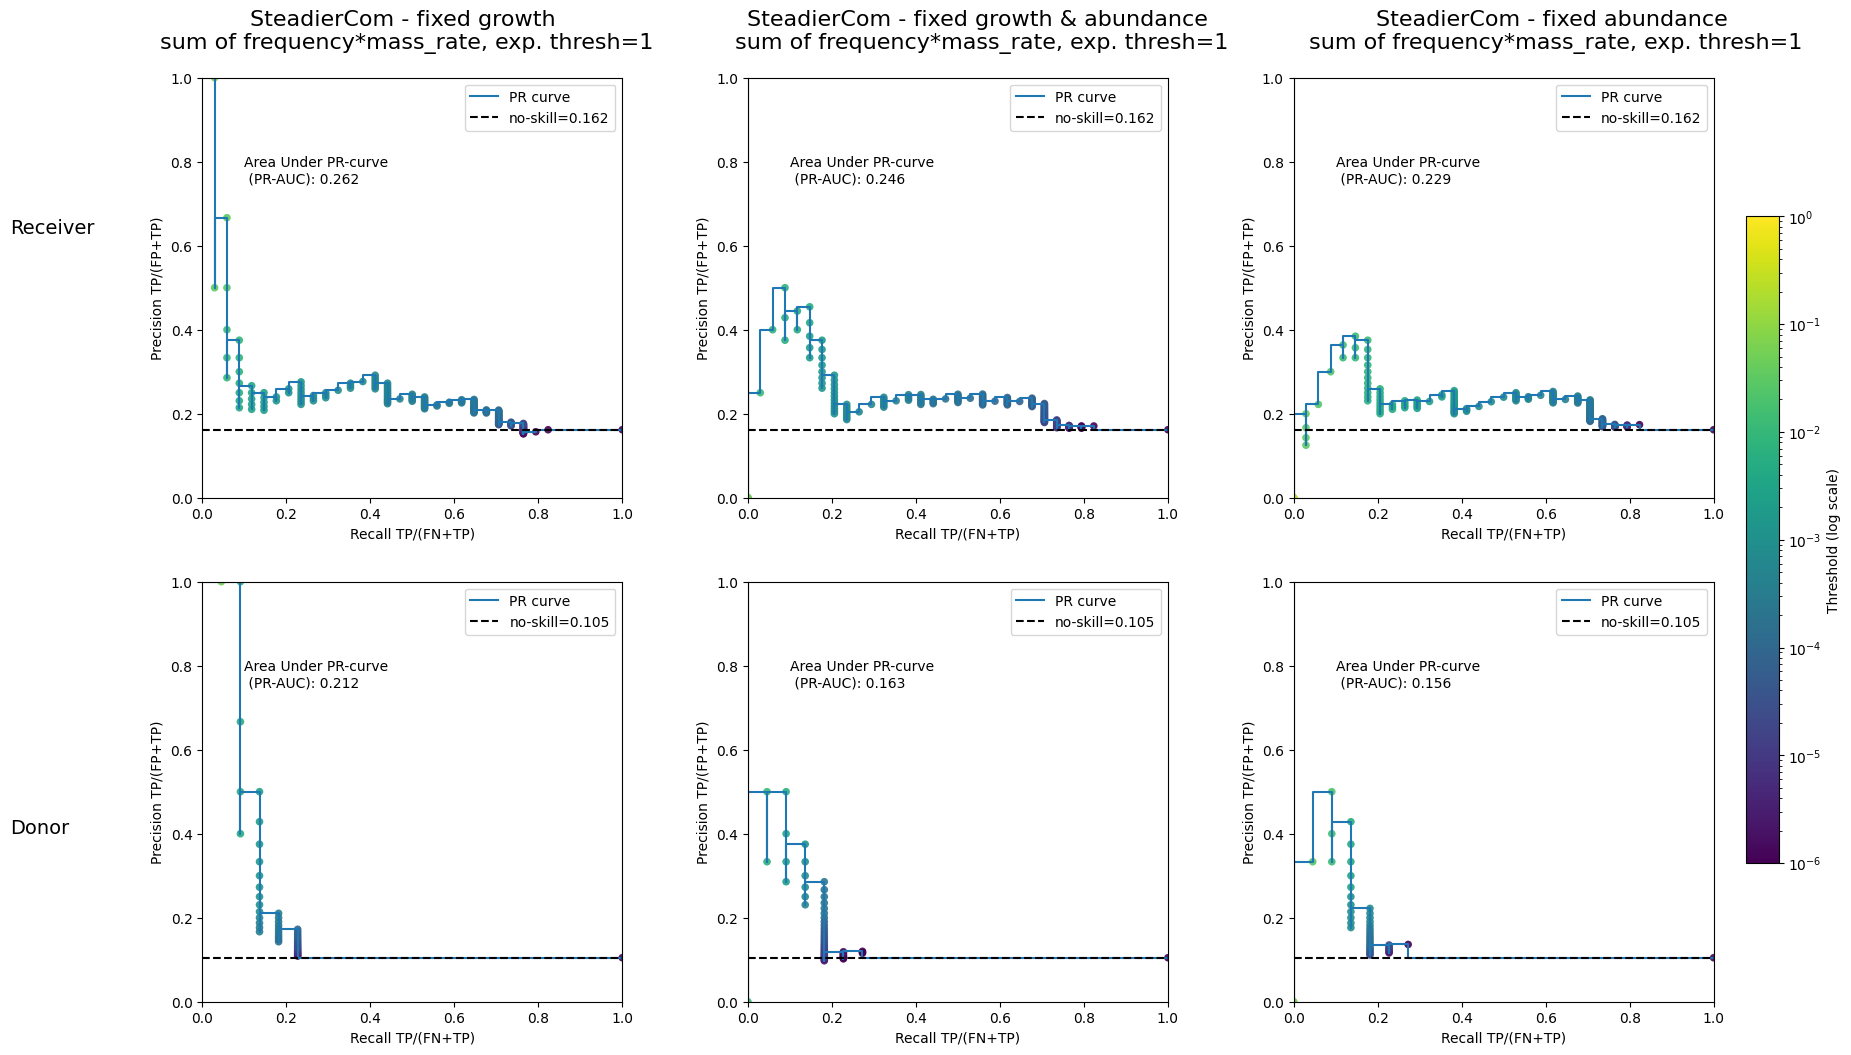

In [27]:
fig,axs = diagnostic.plot_diagnostic_curves_method(simulation_dict,
                                                    signal_exp,
                                                    simulation_method="steadiercom",
                                                    metric="frequency*mass_rate",
                                                    met_column="met_group",
                                                    agg_method="sum")

INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes compounds not in experimental data


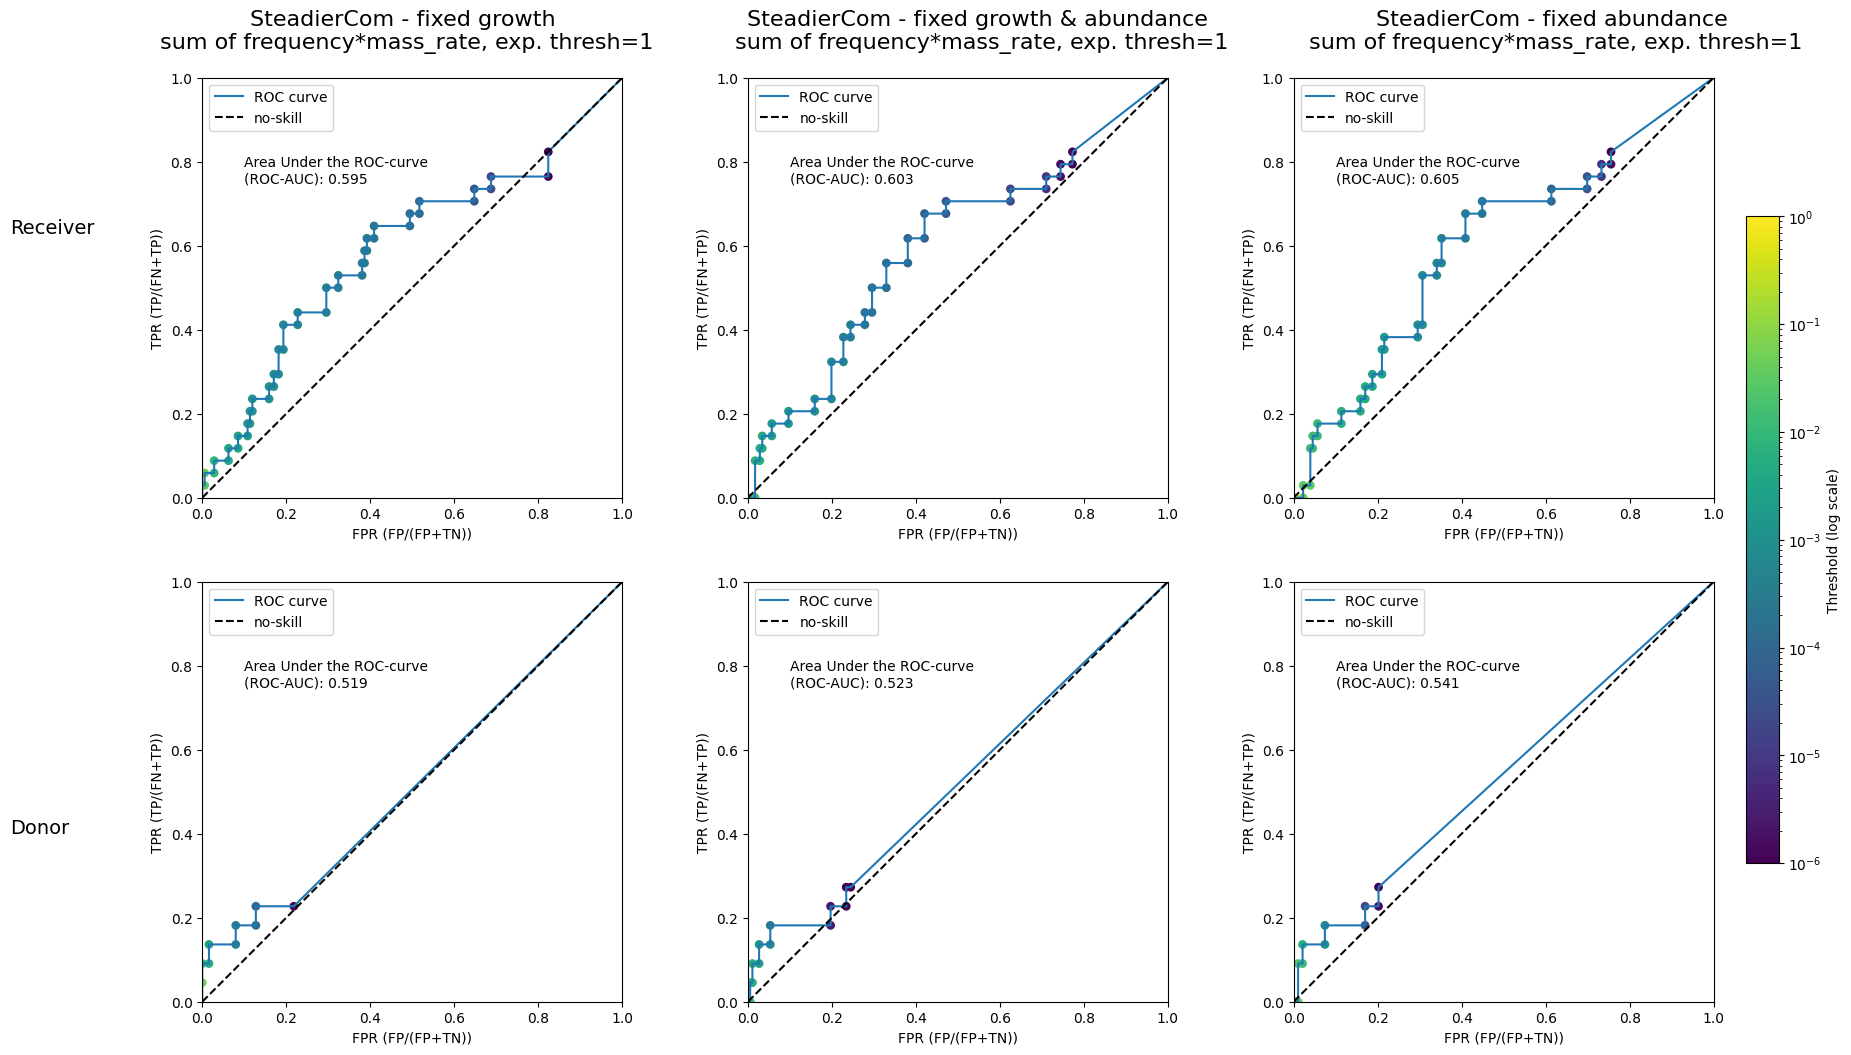

In [28]:
fig,axs = diagnostic.plot_diagnostic_curves_method(simulation_dict,
                                                    signal_exp,
                                                    simulation_method="steadiercom",
                                                    metric="frequency*mass_rate",
                                                    PR_or_ROC="ROC",
                                                    met_column="met_group",
                                                    agg_method="sum")